## Step 1 — Install libraries

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from google.colab import files
import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2 — Load the dataset

In [3]:
uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("Please upload KT_GameBox_1.csv")
DATASET_PATH = csv_files[0]

# The project guide recommends starting with 100,000 rows.
MAX_ROWS = 100_000
df = pd.read_csv(DATASET_PATH, nrows=MAX_ROWS, low_memory=False)

print("Dataset Shape:")
print(df.shape)
display(df.head())

Saving KT_GameBox_1.csv to KT_GameBox_1.csv
Dataset Shape:
(100000, 7)


,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-10-05 14:28:49.564595,192.0.0.2,10.215.173.2,TCP,60,47254 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2,2022-10-05 14:28:51.317163,10.215.173.1,10.215.173.2,DNS,68,Standard query 0xa610 A gbc.play.ktgamebox.com
2,3,2022-10-05 14:28:51.348247,10.215.173.2,10.215.173.1,DNS,168,Standard query response 0xa610 A gbc.play.ktga...
3,4,2022-10-05 14:28:51.351537,10.215.173.1,211.252.120.14,TCP,60,60014 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...
4,5,2022-10-05 14:28:51.372722,211.252.120.14,10.215.173.1,TCP,48,"443 > 60014 [SYN, ACK] Seq=0 Ack=1 Win=2048 ..."


## Step 3 — Check the dataset

In [4]:
print("Number of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nBasic information:")
df.info()

print("\nStatistical information:")
display(df.describe(include="all"))

Number of rows and columns:
(100000, 7)

Column names:
Index(['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info'], dtype='object')

Data types:
No.             int64
Time           object
Source         object
Destination    object
Protocol       object
Length          int64
Info           object
dtype: object

Basic information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   No.          100000 non-null  int64 
 1   Time         100000 non-null  object
 2   Source       100000 non-null  object
 3   Destination  100000 non-null  object
 4   Protocol     100000 non-null  object
 5   Length       100000 non-null  int64 
 6   Info         100000 non-null  object
dtypes: int64(2), object(5)
memory usage: 5.3+ MB

Statistical information:


,No.,Time,Source,Destination,Protocol,Length,Info
count,100000.000000,100000,100000,100000,100000,100000.000000,100000
unique,NaN,100000,7,7,6,NaN,15103
top,NaN,2022-10-05 14:28:49.564595,183.110.235.46,10.215.173.1,UDP,NaN,41299 > 37181 Len=1272
freq,NaN,1,86664,86743,85944,NaN,74444
mean,50000.500000,NaN,NaN,NaN,NaN,1261.800620,NaN
std,28867.657797,NaN,NaN,NaN,NaN,976.958884,NaN
min,1.000000,NaN,NaN,NaN,NaN,32.000000,NaN
25%,25000.750000,NaN,NaN,NaN,NaN,1300.000000,NaN
50%,50000.500000,NaN,NaN,NaN,NaN,1300.000000,NaN
75%,75000.250000,NaN,NaN,NaN,NaN,1300.000000,NaN


## Step 4 — Check missing values

In [5]:
print(df.isnull().sum())


df = df.dropna(subset=["Protocol"])


df = df.dropna()

print("\nMissing values after cleaning:")
print(df.isnull().sum())

No.            0
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
dtype: int64

Missing values after cleaning:
No.            0
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
dtype: int64


## Step 5 — Check duplicate records

In [6]:
print("Duplicate records:", df.duplicated().sum())
df = df.drop_duplicates()
print("Dataset shape:", df.shape)

Duplicate records: 0
Dataset shape: (100000, 7)


## Step 6 — Understand the target variable

In [7]:
print("Unique protocols:")
print(df["Protocol"].unique())

print("\nProtocol counts:")
print(df["Protocol"].value_counts())

Unique protocols:
['TCP' 'DNS' 'TLSv1.3' 'TLSv1' 'UDP' 'TLSv1.2']

Protocol counts:
Protocol
UDP        85944
TCP        13876
TLSv1        115
TLSv1.3       42
TLSv1.2       13
DNS           10
Name: count, dtype: int64


## Step 7 — Visualize protocols

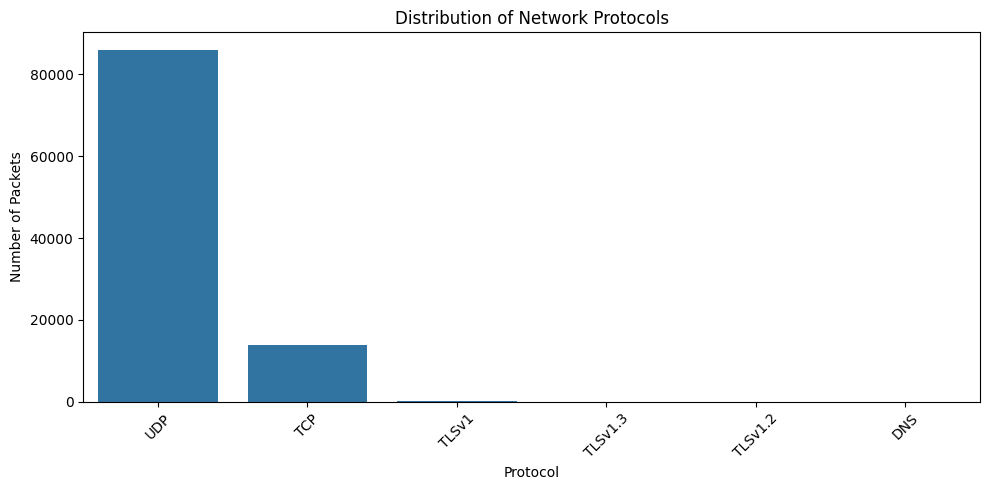

In [8]:
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)
plt.xticks(rotation=45)
plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.tight_layout()
plt.show()

## Step 8 — Analyze packet length

,Length
count,100000.000000
mean,1261.800620
std,976.958884
min,32.000000
25%,1300.000000
50%,1300.000000
75%,1300.000000
max,10000.000000


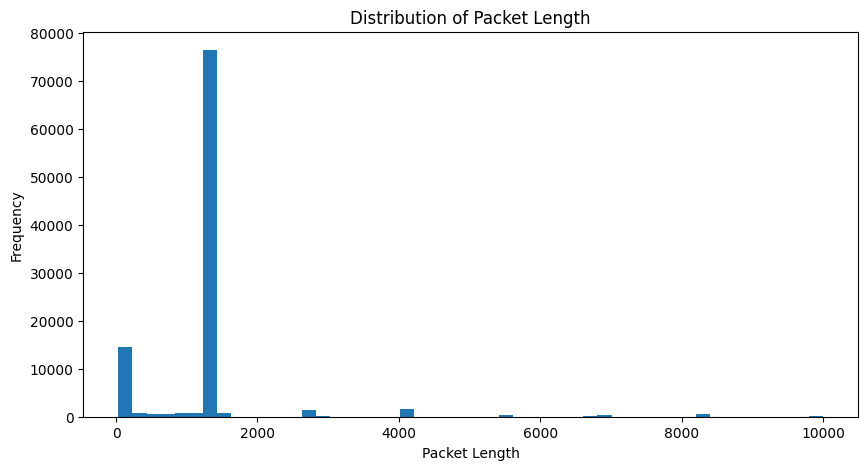

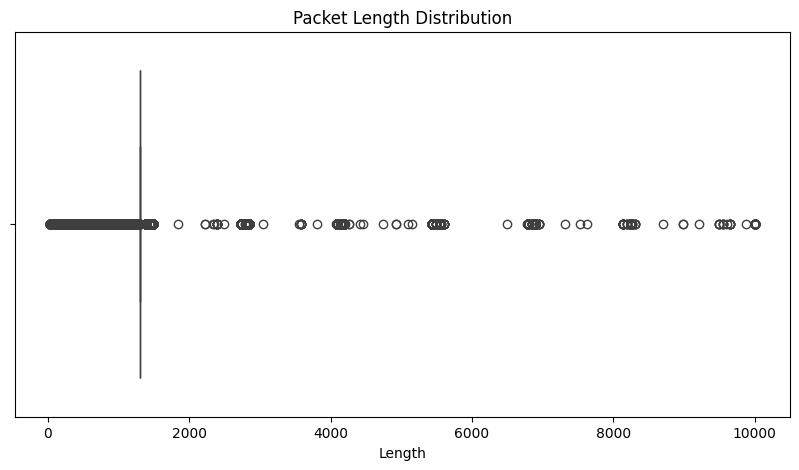

In [9]:
df["Length"] = pd.to_numeric(df["Length"], errors="coerce")
display(df["Length"].describe())

plt.figure(figsize=(10, 5))
plt.hist(df["Length"].dropna(), bins=50)
plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(x=df["Length"])
plt.title("Packet Length Distribution")
plt.show()

## Step 9 — Create useful features

In [10]:
print(df["Time"].head())

df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second

display(df[["Time", "Hour", "Minute", "Second"]].head())

0    2022-10-05 14:28:49.564595
1    2022-10-05 14:28:51.317163
2    2022-10-05 14:28:51.348247
3    2022-10-05 14:28:51.351537
4    2022-10-05 14:28:51.372722
Name: Time, dtype: object


,Time,Hour,Minute,Second
0,2022-10-05 14:28:49.564595,14,28,49
1,2022-10-05 14:28:51.317163,14,28,51
2,2022-10-05 14:28:51.348247,14,28,51
3,2022-10-05 14:28:51.351537,14,28,51
4,2022-10-05 14:28:51.372722,14,28,51


## Step 10 — What features should we use?

As specified in the project document, use `Length`, `Hour`, `Minute`, and `Second` as features, and `Protocol` as the target.

`Source` and `Destination` are not used in this beginner model because IP addresses can have many unique values.

In [11]:
X = df[[
    "Length",
    "Hour",
    "Minute",
    "Second"
]]

y = df["Protocol"]

## Step 11 — Check X and y

In [12]:
print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

print("X shape:", X.shape)
print("y shape:", y.shape)

Features:


,Length,Hour,Minute,Second
0,60,14,28,49
1,68,14,28,51
2,168,14,28,51
3,60,14,28,51
4,48,14,28,51



Target:


,Protocol
0,TCP
1,DNS
2,DNS
3,TCP
4,TCP


X shape: (100000, 4)
y shape: (100000,)


## Step 12 — Handle missing feature values

In [13]:
print(X.isnull().sum())
X = X.fillna(0)

Length    0
Hour      0
Minute    0
Second    0
dtype: int64


## Step 13 — Encode the Protocol

In [14]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Protocol classes:")
print(label_encoder.classes_)

print("First 20 encoded values:")
print(y_encoded[:20])

Protocol classes:
['DNS' 'TCP' 'TLSv1' 'TLSv1.2' 'TLSv1.3' 'UDP']
First 20 encoded values:
[1 0 0 1 1 1 4 1 0 4 1 4 1 4 1 4 1 0 1 4]


## Step 14 — Split the dataset

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 80000
Testing samples: 20000


## Step 15 — Feature scaling

In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


## Step 16 — Model 1: Logistic Regression

In [17]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr * 100, "%")

Logistic Regression Accuracy: 87.775 %


## Step 17 — Classification report

In [18]:
print(classification_report(
    y_test,
    y_pred_lr,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=[str(c) for c in label_encoder.classes_],
    zero_division=0
))

              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         2
         TCP       1.00      0.13      0.23      2775
       TLSv1       0.00      0.00      0.00        23
     TLSv1.2       0.00      0.00      0.00         3
     TLSv1.3       0.00      0.00      0.00         8
         UDP       0.88      1.00      0.93     17189

    accuracy                           0.88     20000
   macro avg       0.31      0.19      0.19     20000
weighted avg       0.89      0.88      0.83     20000



## Step 18 — Confusion Matrix

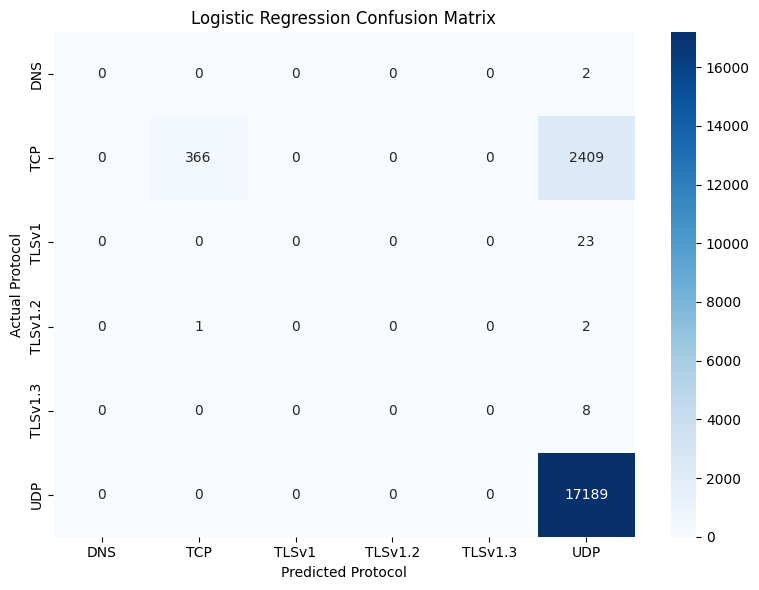

In [19]:
cm = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 19 — Model 2: KNN

In [20]:
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", accuracy_knn * 100, "%")

KNN Accuracy: 99.63 %


## Step 20 — Model 3: Decision Tree

In [21]:
dt_model = DecisionTreeClassifier(random_state=42, max_depth=10)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt * 100, "%")

Decision Tree Accuracy: 99.83999999999999 %


## Step 21 — Visualize the Decision Tree

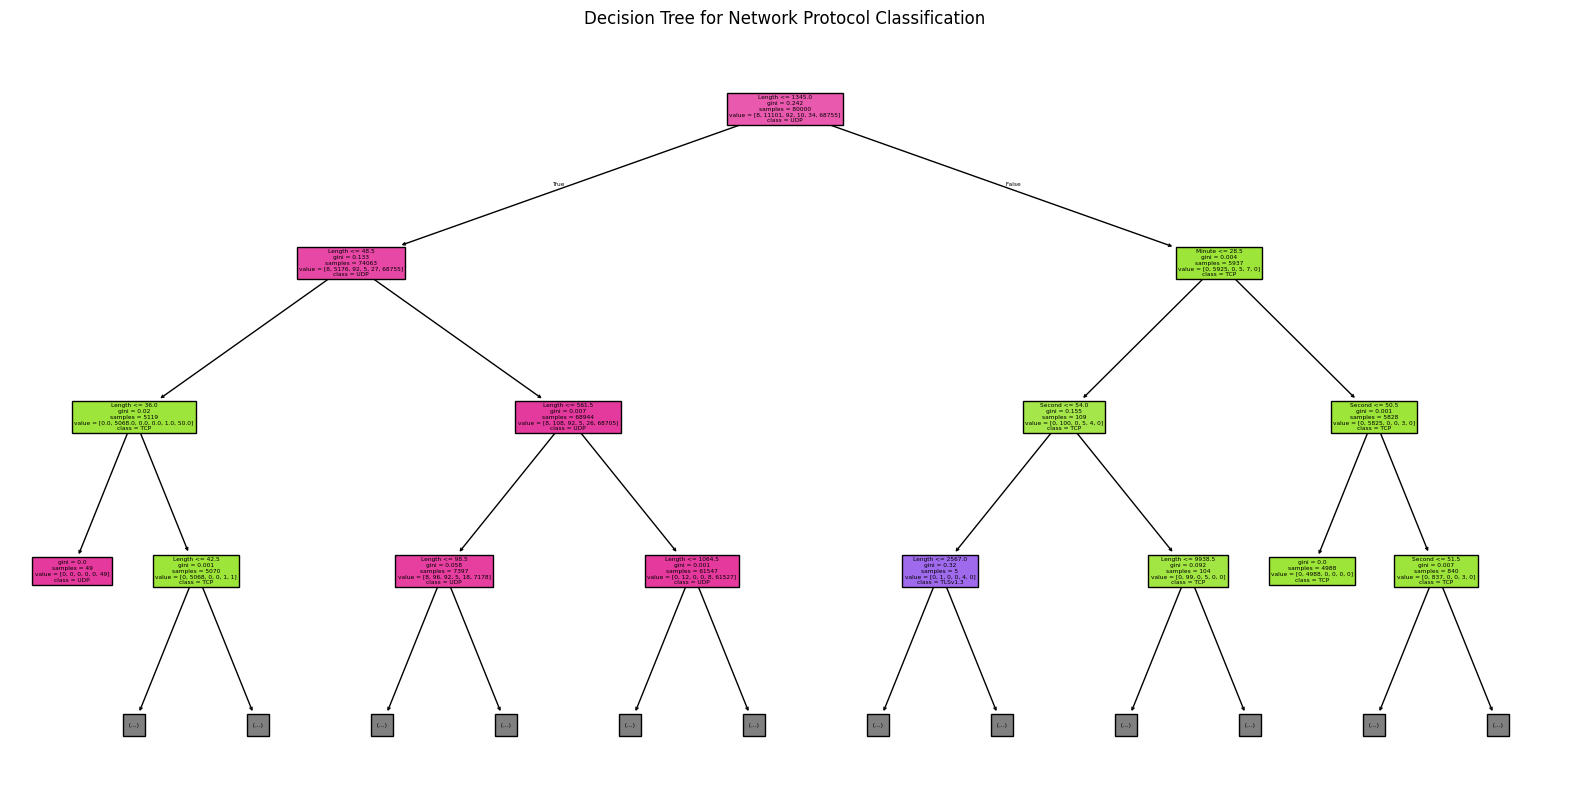

In [22]:
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in label_encoder.classes_],
    filled=True,
    max_depth=3
)
plt.title("Decision Tree for Network Protocol Classification")
plt.show()

## Step 22 — Model 4: Random Forest

In [23]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf * 100, "%")

Random Forest Accuracy: 99.79 %


## Step 23 — Compare all models

In [24]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_knn,
        accuracy_dt,
        accuracy_rf
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100
display(results)

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.87775,87.775
1,KNN,0.99630,99.630
2,Decision Tree,0.99840,99.840
3,Random Forest,0.99790,99.790


## Step 24 — Plot model comparison

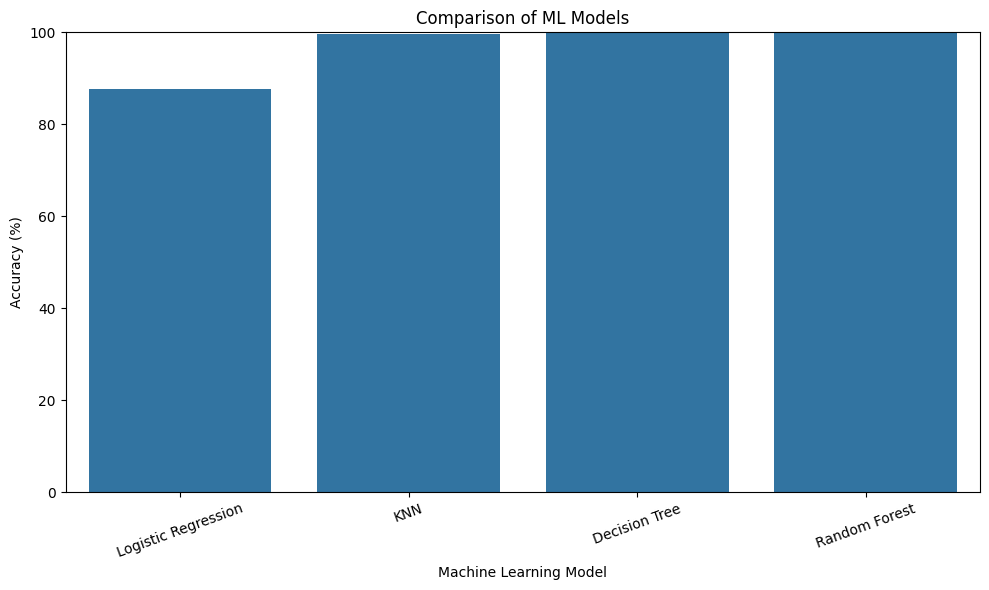

In [25]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.title("Comparison of ML Models")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")
plt.tight_layout()
plt.show()

## Step 25 — Find the best model

In [26]:
best_model = results.loc[results["Accuracy"].idxmax()]
print("Best Model:")
print(best_model)

Best Model:
Model           Decision Tree
Accuracy               0.9984
Accuracy (%)            99.84
Name: 2, dtype: object


## Step 26 — Feature importance

,Feature,Importance
0,Length,0.985337
2,Minute,0.009183
3,Second,0.005480
1,Hour,0.000000


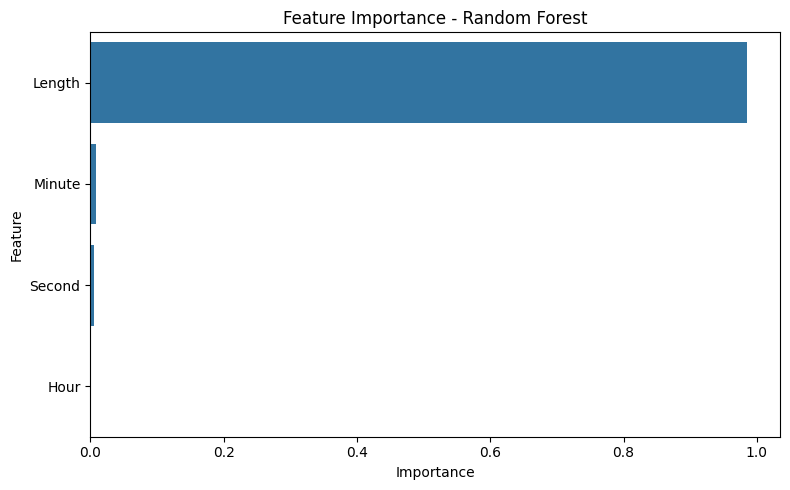

In [27]:
importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)
plt.title("Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

## Step 27 — Detailed evaluation of Random Forest

              precision    recall  f1-score   support

         DNS       0.50      0.50      0.50         2
         TCP       1.00      1.00      1.00      2775
       TLSv1       0.58      0.48      0.52        23
     TLSv1.2       0.00      0.00      0.00         3
     TLSv1.3       1.00      0.50      0.67         8
         UDP       1.00      1.00      1.00     17189

    accuracy                           1.00     20000
   macro avg       0.68      0.58      0.61     20000
weighted avg       1.00      1.00      1.00     20000



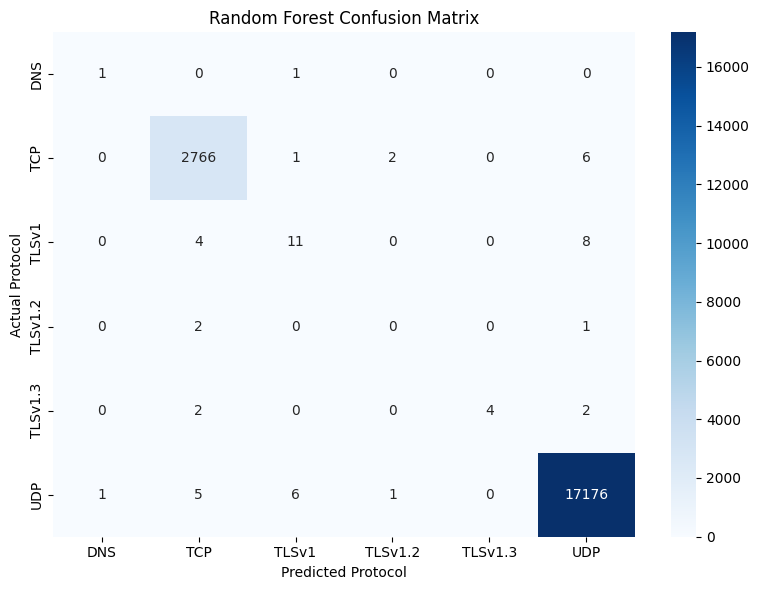

In [28]:
print(classification_report(
    y_test,
    y_pred_rf,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=[str(c) for c in label_encoder.classes_],
    zero_division=0
))

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 28 — Predict a new packet

In [29]:
new_packet = pd.DataFrame({
    "Length": [64],
    "Hour": [10],
    "Minute": [30],
    "Second": [15]
})

prediction = rf_model.predict(new_packet)

predicted_protocol = label_encoder.inverse_transform(prediction)

print("Predicted Protocol:", predicted_protocol[0])

Predicted Protocol: UDP
